# 01: Climate Time-Series Exploratory Data Analysis
## Overview
This notebook performs exploratory data analysis on the Berkeley Earth Surface Temperature dataset. 
The goal is to inspect data quality, analyze historical temperature trends, and understand seasonality 
and missingness patterns before building baseline forecasting models.

## Objectives
- Load raw global temperature CSV data and inspect column structures/types.
- Analyze missing value distributions and identify data coverage start dates (e.g., pre- vs. post-1850).
- Visualize long-term global warming trends and seasonal variation.
- Export cleaned, truncated time-series data to `data/processed/` for model training.

## Dataset
- **Source:** Berkeley Earth Surface Temperature (`GlobalTemperatures.csv`) 
Kaggle: https://www.kaggle.com/datasets/berkeleyearth/climate-change-earth-surface-temperature-data
- **Granularity:** Monthly global average temperature records


### 1. Setup and Data Loading

Initial Setup: Import Packages

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Download the Data

In [3]:
file_path = '../data/raw/GlobalTemperatures.csv'

df = pd.read_csv(file_path)
print(df.shape)
df.head()

(3192, 9)


,dt,LandAverageTemperature,LandAverageTemperatureUncertainty,LandMaxTemperature,LandMaxTemperatureUncertainty,LandMinTemperature,LandMinTemperatureUncertainty,LandAndOceanAverageTemperature,LandAndOceanAverageTemperatureUncertainty
0,1750-01-01,3.034,3.574,NaN,NaN,NaN,NaN,NaN,NaN
1,1750-02-01,3.083,3.702,NaN,NaN,NaN,NaN,NaN,NaN
2,1750-03-01,5.626,3.076,NaN,NaN,NaN,NaN,NaN,NaN
3,1750-04-01,8.490,2.451,NaN,NaN,NaN,NaN,NaN,NaN
4,1750-05-01,11.573,2.072,NaN,NaN,NaN,NaN,NaN,NaN


### 2. Initial Data Inspection

Convert `dt` time column to pandas `date_time` valus. 

In [4]:
df['dt'] = pd.to_datetime(df['dt'])
df.head()

,dt,LandAverageTemperature,LandAverageTemperatureUncertainty,LandMaxTemperature,LandMaxTemperatureUncertainty,LandMinTemperature,LandMinTemperatureUncertainty,LandAndOceanAverageTemperature,LandAndOceanAverageTemperatureUncertainty
0,1750-01-01,3.034,3.574,NaN,NaN,NaN,NaN,NaN,NaN
1,1750-02-01,3.083,3.702,NaN,NaN,NaN,NaN,NaN,NaN
2,1750-03-01,5.626,3.076,NaN,NaN,NaN,NaN,NaN,NaN
3,1750-04-01,8.490,2.451,NaN,NaN,NaN,NaN,NaN,NaN
4,1750-05-01,11.573,2.072,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print(df.shape)
print(df.describe)
print(df.info)

(3192, 9)
<bound method NDFrame.describe of              dt  LandAverageTemperature  LandAverageTemperatureUncertainty  \
0    1750-01-01                   3.034                              3.574   
1    1750-02-01                   3.083                              3.702   
2    1750-03-01                   5.626                              3.076   
3    1750-04-01                   8.490                              2.451   
4    1750-05-01                  11.573                              2.072   
...         ...                     ...                                ...   
3187 2015-08-01                  14.755                              0.072   
3188 2015-09-01                  12.999                              0.079   
3189 2015-10-01                  10.801                              0.102   
3190 2015-11-01                   7.433                              0.119   
3191 2015-12-01                   5.518                              0.100   

      LandMaxTemper

In [6]:
df.tail()

,dt,LandAverageTemperature,LandAverageTemperatureUncertainty,LandMaxTemperature,LandMaxTemperatureUncertainty,LandMinTemperature,LandMinTemperatureUncertainty,LandAndOceanAverageTemperature,LandAndOceanAverageTemperatureUncertainty
3187,2015-08-01,14.755,0.072,20.699,0.110,9.005,0.170,17.589,0.057
3188,2015-09-01,12.999,0.079,18.845,0.088,7.199,0.229,17.049,0.058
3189,2015-10-01,10.801,0.102,16.450,0.059,5.232,0.115,16.290,0.062
3190,2015-11-01,7.433,0.119,12.892,0.093,2.157,0.106,15.252,0.063
3191,2015-12-01,5.518,0.100,10.725,0.154,0.287,0.099,14.774,0.062


Check for NaNs across each feature:

In [7]:
print(df.isna().sum().to_dict())

{'dt': 0, 'LandAverageTemperature': 12, 'LandAverageTemperatureUncertainty': 12, 'LandMaxTemperature': 1200, 'LandMaxTemperatureUncertainty': 1200, 'LandMinTemperature': 1200, 'LandMinTemperatureUncertainty': 1200, 'LandAndOceanAverageTemperature': 1200, 'LandAndOceanAverageTemperatureUncertainty': 1200}


### 2. General Temperature Trends

In [8]:
print(f'First Recorded Date: {df['dt'].min()}')
print(f'Last Recorded Date: {df['dt'].max()}')

First Recorded Date: 1750-01-01 00:00:00
Last Recorded Date: 2015-12-01 00:00:00


Data records span from 1750 to 2015. 

Plot Average Land Temperatures over entire dataset:

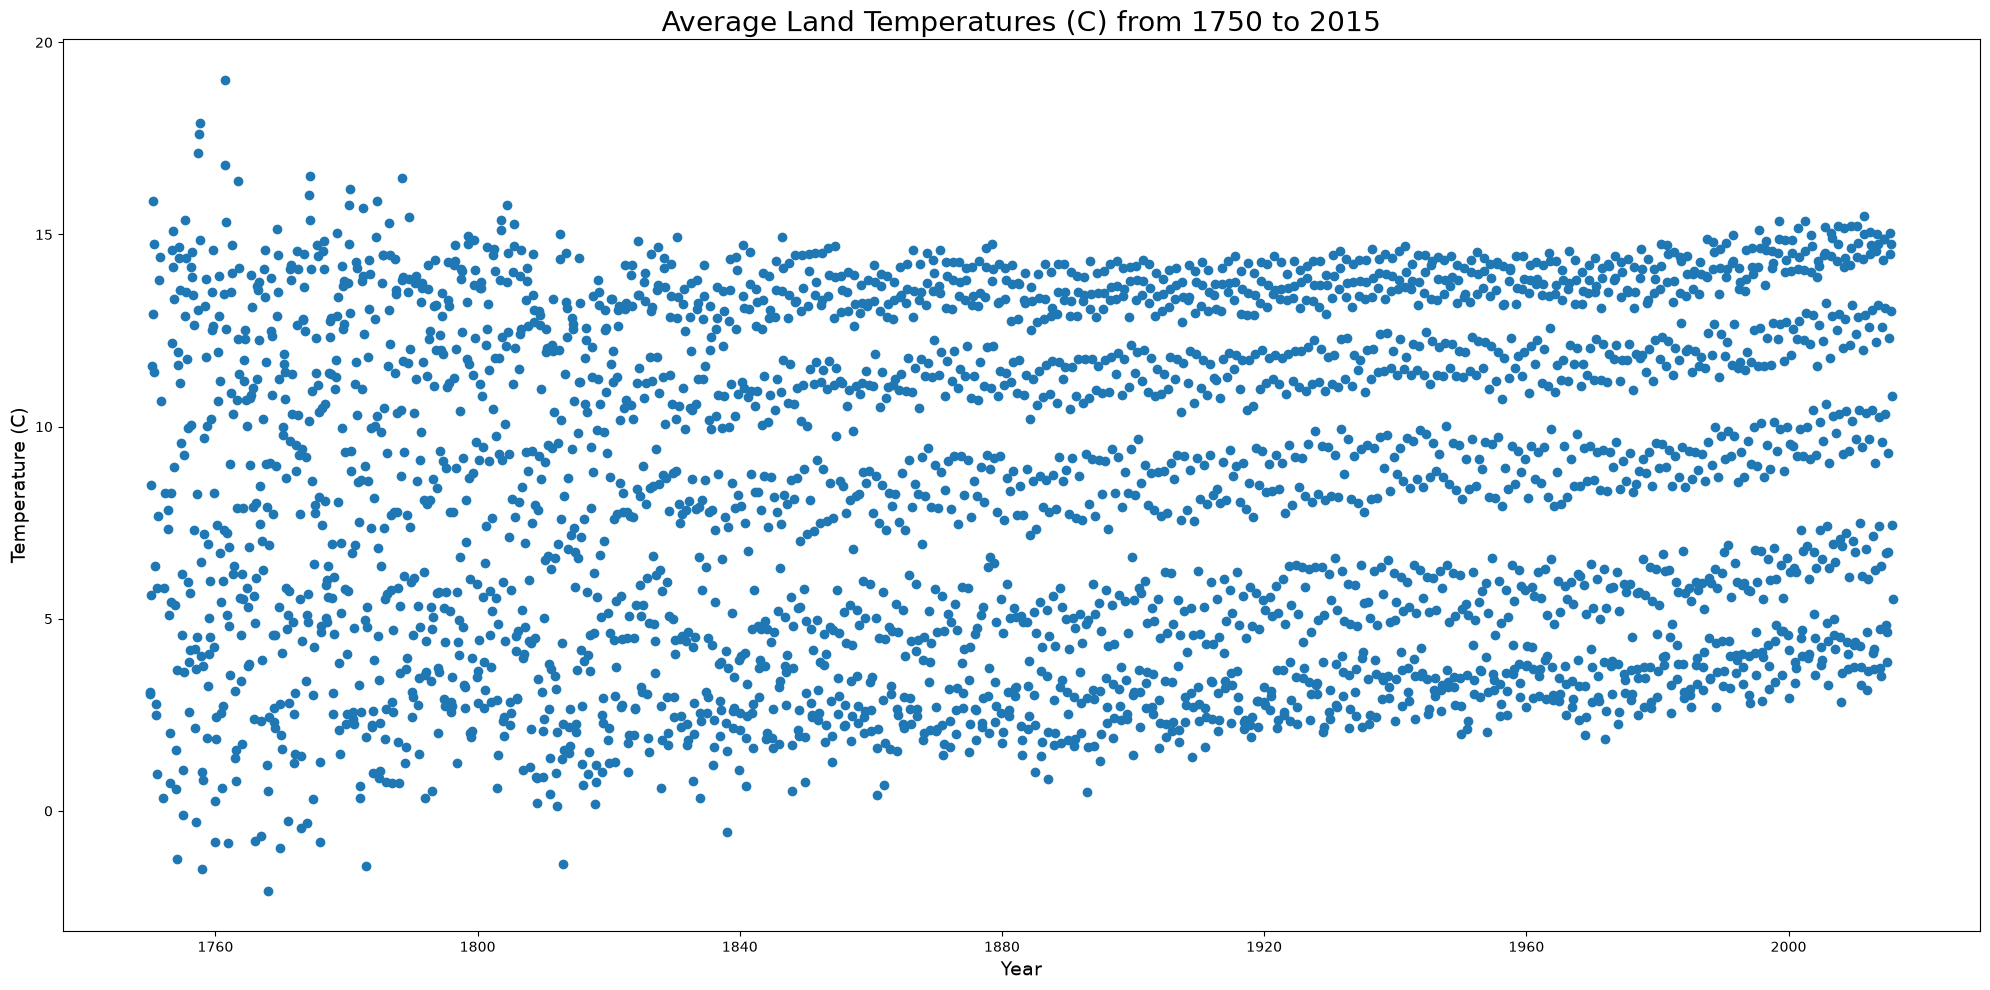

In [9]:
first_year = df['dt'].dt.year.min()
last_year = df['dt'].dt.year.max()

# Scatter plot of average land temperatures across years
plt.figure(figsize=(20, 10))
plt.scatter(x=df['dt'], y=df['LandAverageTemperature'])
plt.xlabel('Year', fontsize=14)
plt.ylabel('Temperature (C)', fontsize=14)
plt.title(f'Average Land Temperatures (C) from {first_year} to {last_year}', fontsize=20)
plt.tight_layout()
plt.show()

Scatter plot of Average Land and Ocean Temperature across years

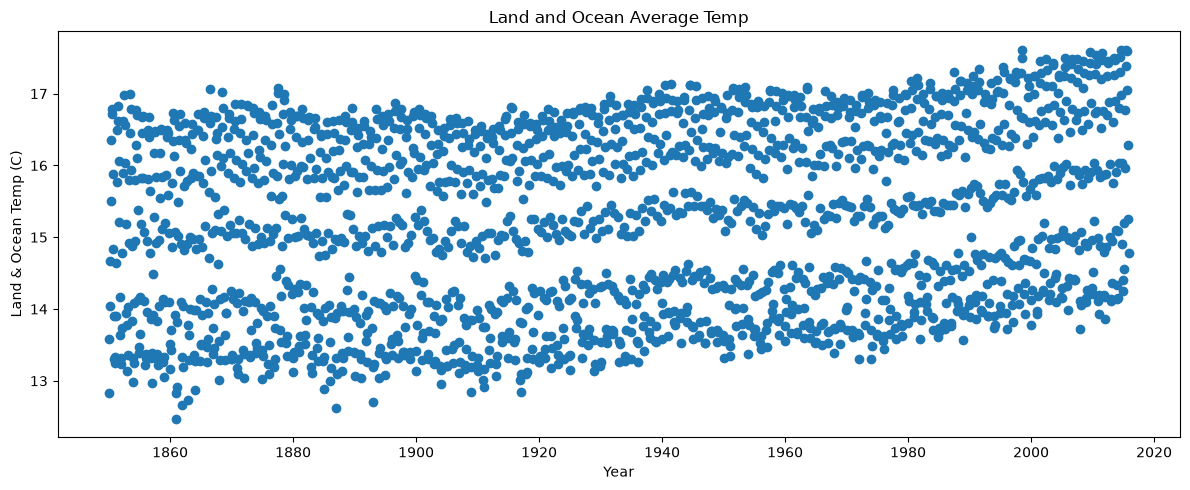

In [10]:
plt.figure(figsize=(12, 5))
plt.scatter(x = df['dt'], y = df['LandAndOceanAverageTemperature'])
plt.xlabel('Year')
plt.ylabel('Land & Ocean Temp (C)')
plt.title('Land and Ocean Average Temp')
plt.tight_layout()
plt.show()

Histogram of the Average Land Temperatures 

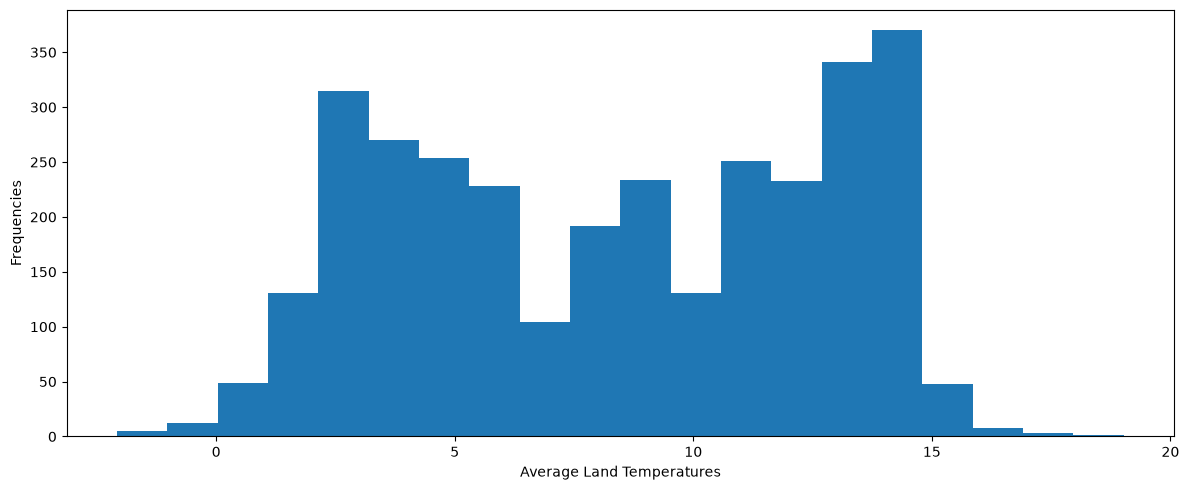

In [11]:
plt.figure(figsize=(12, 5))
plt.hist(df['LandAverageTemperature'], bins=20)
plt.xlabel('Average Land Temperatures')
plt.ylabel('Frequencies')
plt.tight_layout()
plt.show()

### 3. Seasonality

We create a new column for months, derived from the `dt` time column. Then, we group by it to inspect monthly trends in the data. 

In [16]:
df['month'] = df['dt'].dt.month
months = df.groupby('month')
print(months.groups)

# Look at average temperatures for each month
(months['LandAverageTemperature'].mean())

{1: [0, 12, 24, 36, 48, 60, 72, 84, 96, 108, 120, 132, 144, 156, 168, 180, 192, 204, 216, 228, 240, 252, 264, 276, 288, 300, 312, 324, 336, 348, 360, 372, 384, 396, 408, 420, 432, 444, 456, 468, 480, 492, 504, 516, 528, 540, 552, 564, 576, 588, 600, 612, 624, 636, 648, 660, 672, 684, 696, 708, 720, 732, 744, 756, 768, 780, 792, 804, 816, 828, 840, 852, 864, 876, 888, 900, 912, 924, 936, 948, 960, 972, 984, 996, 1008, 1020, 1032, 1044, 1056, 1068, 1080, 1092, 1104, 1116, 1128, 1140, 1152, 1164, 1176, 1188, ...], 2: [1, 13, 25, 37, 49, 61, 73, 85, 97, 109, 121, 133, 145, 157, 169, 181, 193, 205, 217, 229, 241, 253, 265, 277, 289, 301, 313, 325, 337, 349, 361, 373, 385, 397, 409, 421, 433, 445, 457, 469, 481, 493, 505, 517, 529, 541, 553, 565, 577, 589, 601, 613, 625, 637, 649, 661, 673, 685, 697, 709, 721, 733, 745, 757, 769, 781, 793, 805, 817, 829, 841, 853, 865, 877, 889, 901, 913, 925, 937, 949, 961, 973, 985, 997, 1009, 1021, 1033, 1045, 1057, 1069, 1081, 1093, 1105, 1117, 1129, 114

month
1      2.275211
2      2.961521
3      4.956872
4      8.248688
5     11.153053
6     13.343415
7     14.307784
8     13.760064
9     11.723170
10     8.884943
11     5.742405
12     3.198977
Name: LandAverageTemperature, dtype: float64

Bar chart of average temeratures for each month

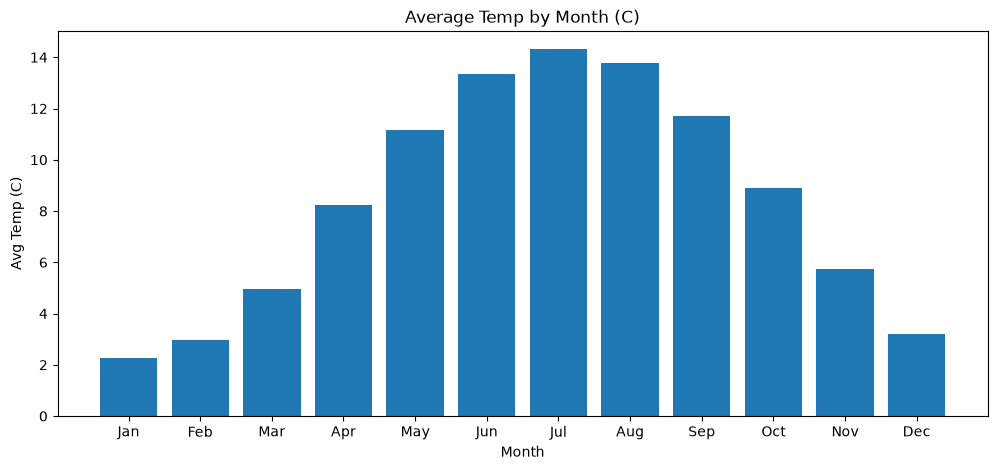

In [ ]:
# Grab list of months
x = list(months.groups.keys())
y = months['LandAverageTemperature'].mean()

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
# Plot bar
plt.figure(figsize=(12, 5))
plt.bar(x, y)
plt.xticks(x, month_names)
plt.xlabel('Month')
plt.ylabel('Avg Temp (C)')
plt.title('Average Temp by Month (C)')
plt.show()

Plot a sample few years by month (1920-1932)

(6, 2)


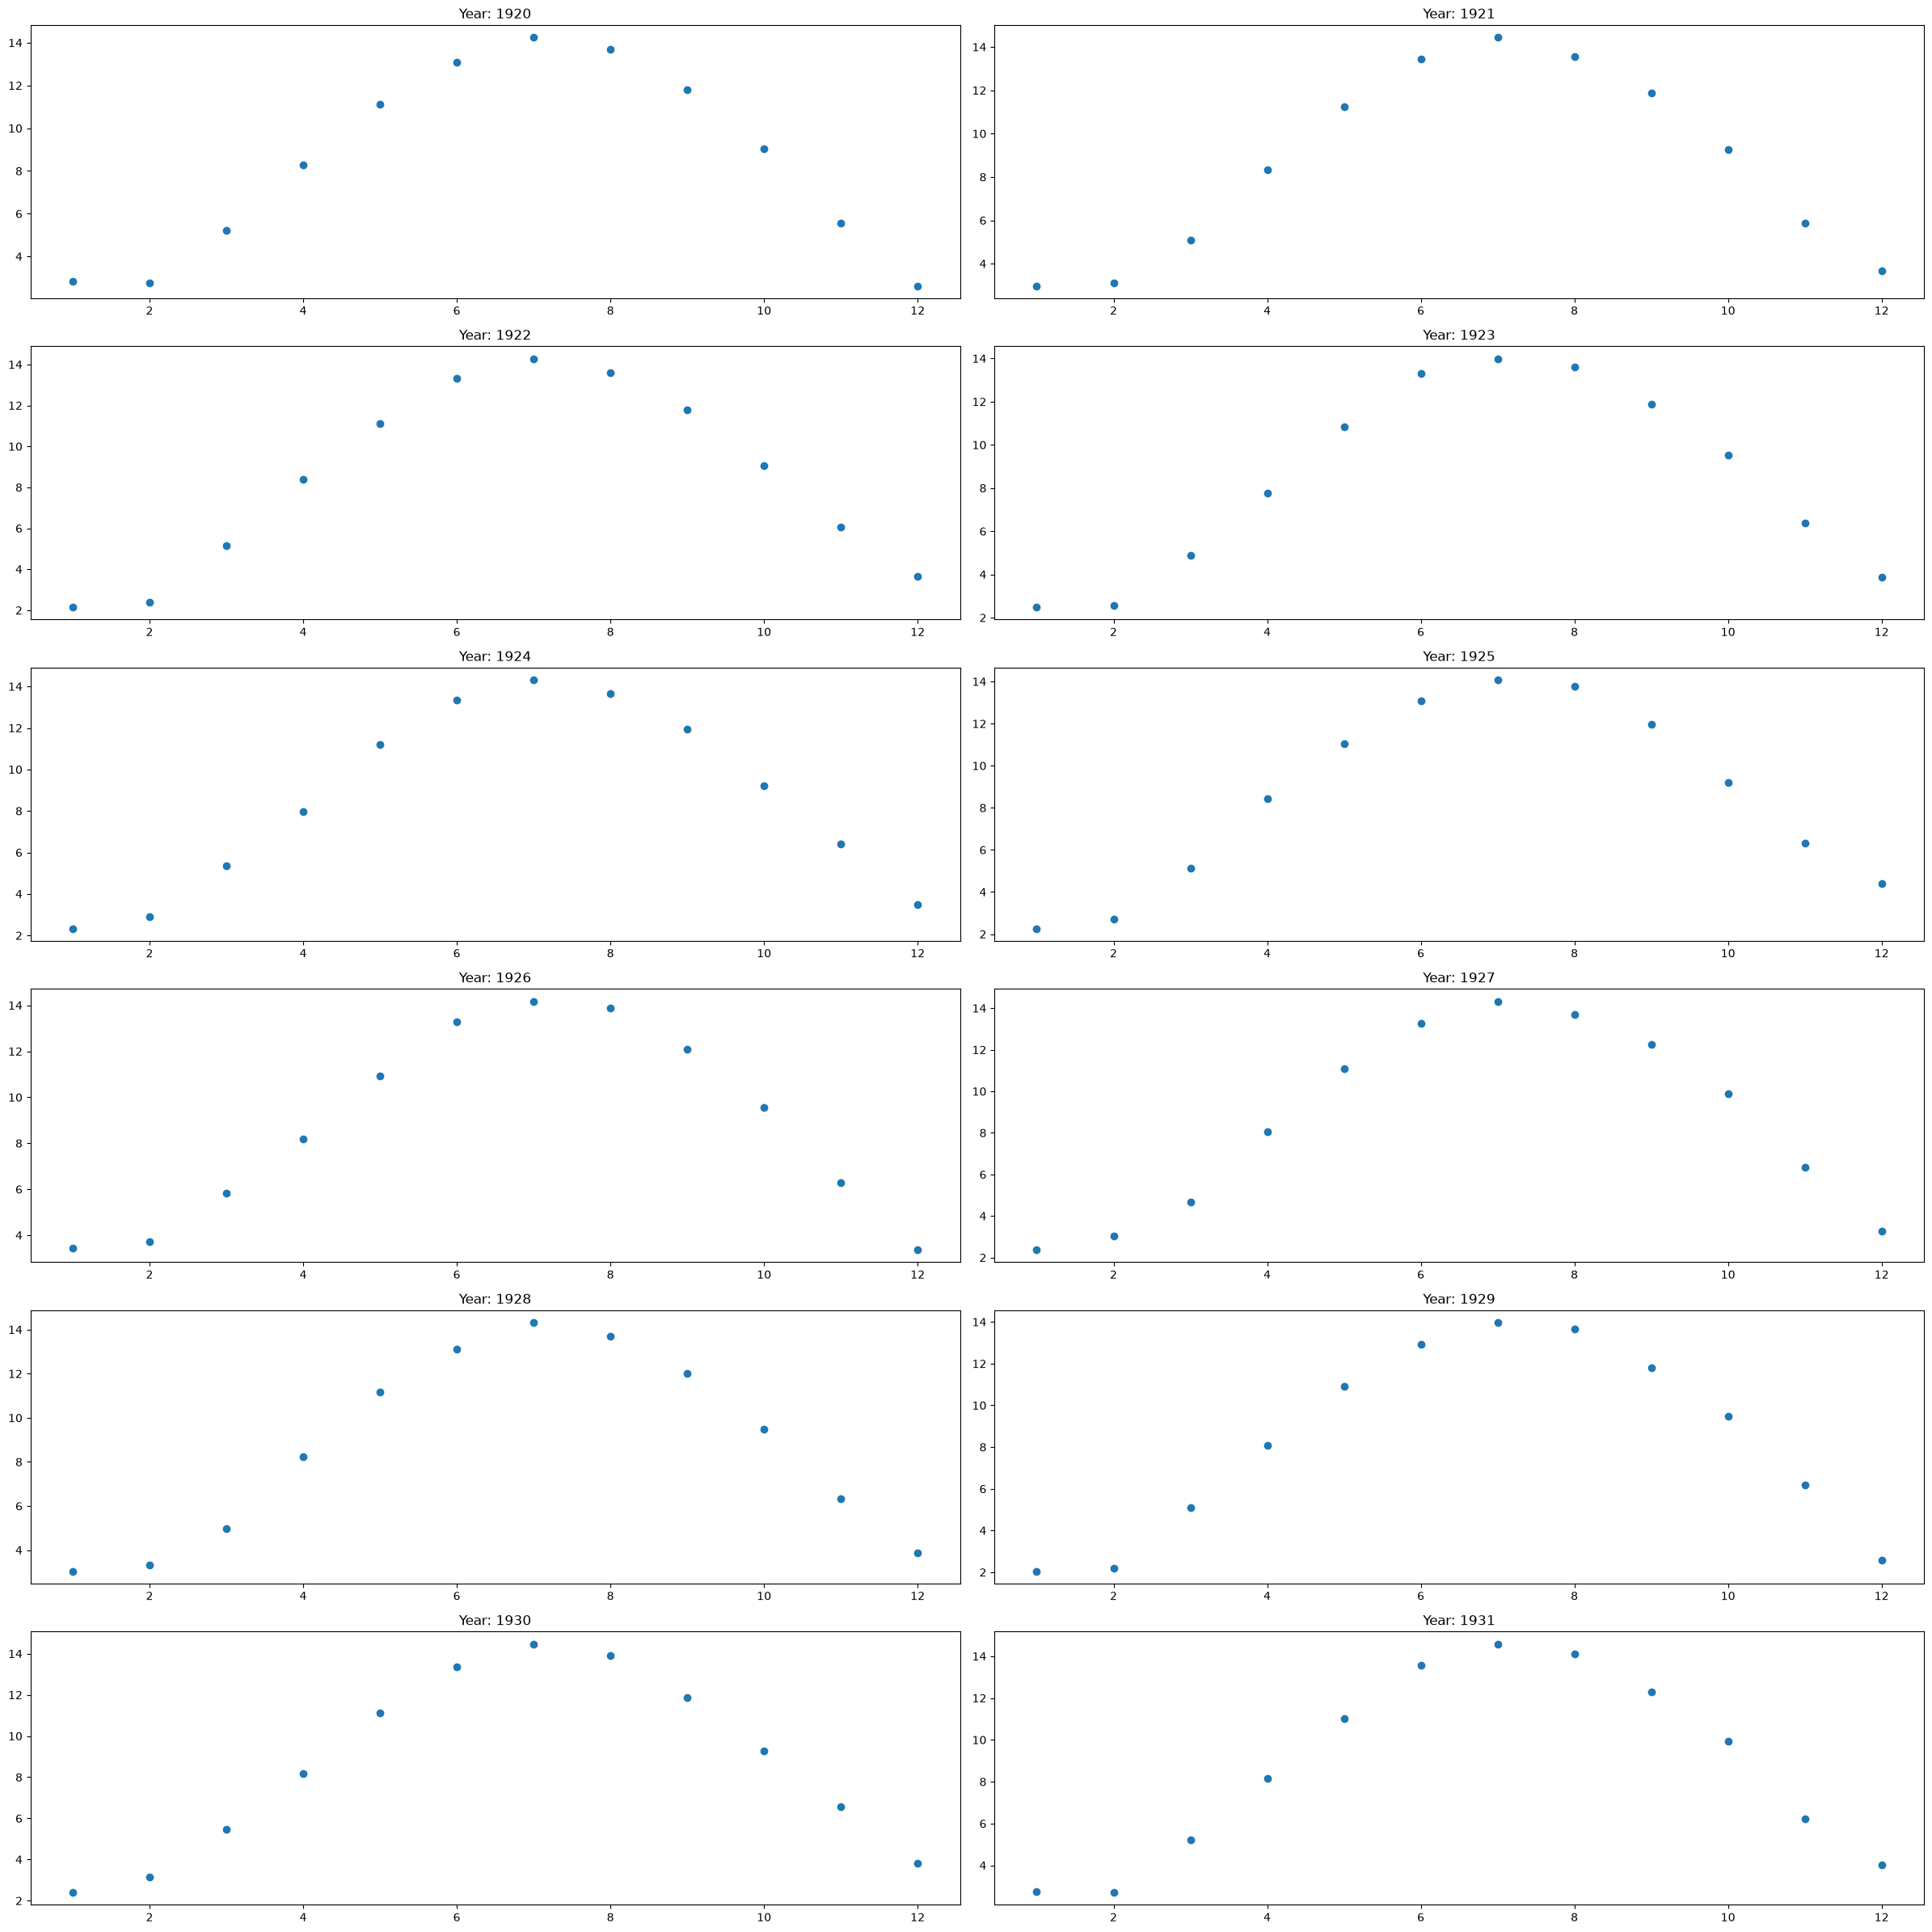

In [19]:
years = [1920 + i for i in range(12)]


fig, ax = plt.subplots(6, 2, figsize=(24, 24))
print(ax.shape)

year_idx = 1920
for i in range(12):

    year_data = df[df['dt'].dt.year == year_idx]

    ax[i // 2, i % 2].scatter(year_data['month'], year_data['LandAverageTemperature'])
    ax[i // 2, i % 2].set_title(f'Year: {year_idx}')
    year_idx += 1

plt.tight_layout()
plt.show()

### 6. Uncertainty

Uncertainty will want to be considered when constructing our models. We should attempt to understand trends in uncertainty for this reason. 

In [ ]:
print(f' Average Land and Ocean Uncertainty for whole dataset: {round(df['LandAndOceanAverageTemperatureUncertainty'].mean(),4)} degrees Celcius')

 Average Land and Ocean Uncertainty for whole dataset: 0.1285 degrees Celcius


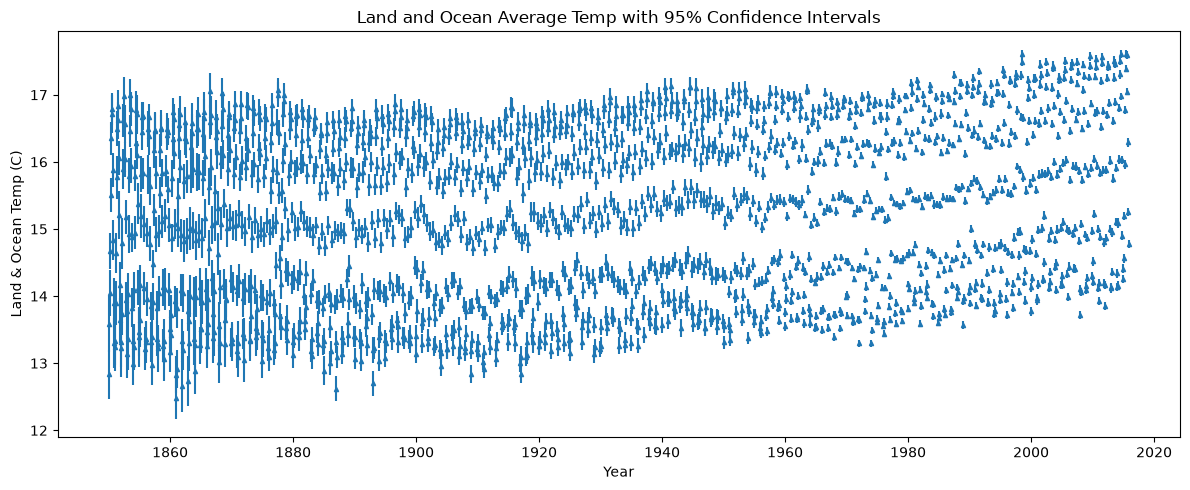

In [32]:
plt.figure(figsize=(12, 5))
plt.errorbar(x = df['dt'], y = df['LandAndOceanAverageTemperature'], yerr = df['LandAndOceanAverageTemperatureUncertainty'], fmt='^', markersize=3)
plt.xlabel('Year')
plt.ylabel('Land & Ocean Temp (C)')
plt.title('Land and Ocean Average Temp with 95% Confidence Intervals')
plt.tight_layout()
plt.show()

(6, 2)


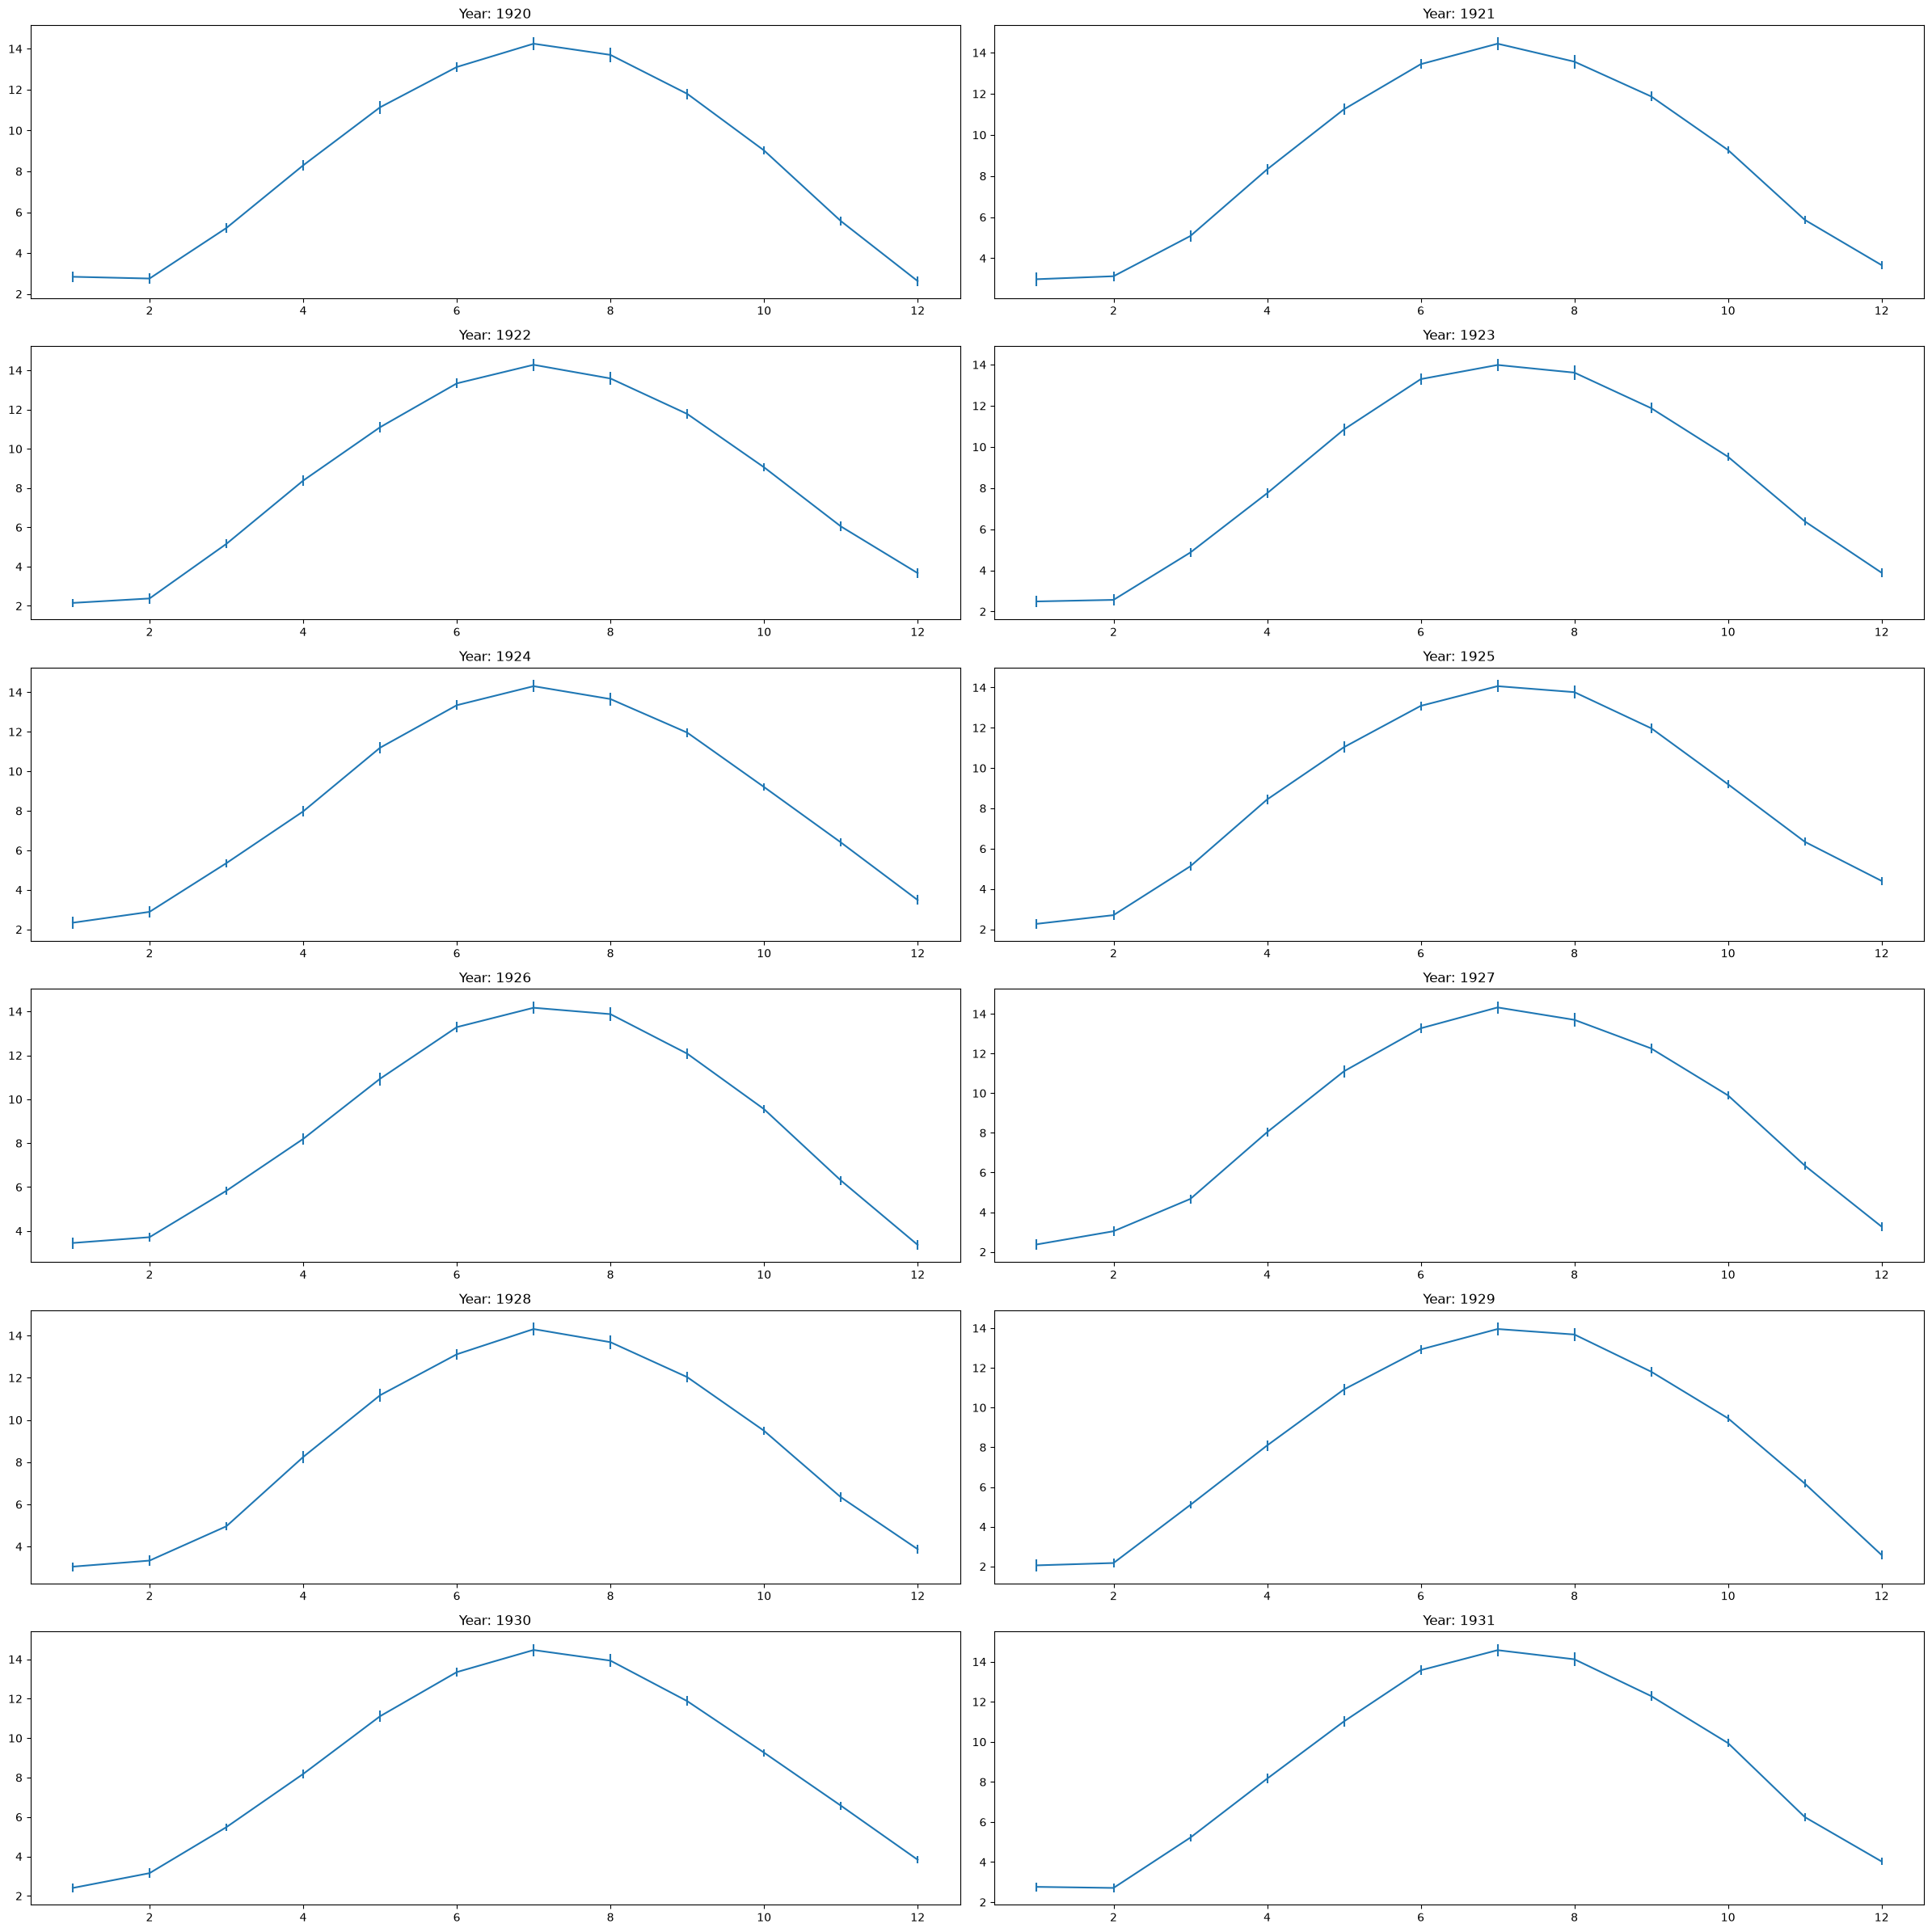

In [30]:
fig, ax = plt.subplots(6, 2, figsize=(24, 24))
print(ax.shape)

year_idx = 1920
for i in range(12):

    year_data = df[df['dt'].dt.year == year_idx]

    ax[i // 2, i % 2].errorbar(year_data['month'], year_data['LandAverageTemperature'], yerr=year_data['LandAverageTemperatureUncertainty'])
    ax[i // 2, i % 2].set_title(f'Year: {year_idx}')
    year_idx += 1

plt.tight_layout()
plt.show()

### 7. Preliminary Findings